# Data Science, 2017 Edition 🕰️
**DLSU Lipa · WCTP 2026 · Jude Teves · Notebook 1 of 2**

> It's 2017. The university's student affairs office asks you: ***"Can you tell us which students are likely to drop out?"***

This is what a typical data science project looked like back then: a CSV, a lot of cleaning and exploring, hand-crafted features, scikit-learn, and a slide at the end. **It's already run**, so just read along during the talk. You can re-run it later in Colab (`Runtime → Run all`).

**The data:** 4,424 real (anonymized) undergraduate students from a higher-education institution in Portugal: background, admission grades, fees, and 1st and 2nd semester results. Each student ended up as **Dropout**, **Enrolled** (still studying) or **Graduate**.
*Source: Realinho et al. (2021), "Predict Students' Dropout and Academic Success", UCI Machine Learning Repository, CC BY 4.0.*

In [1]:
import io, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
pd.set_option("display.max_columns", 50)
GREEN, RUST, GREY = "#2D5F4F", "#C4542A", "#9C9A94"

DATA_URLS = ["https://raw.githubusercontent.com/Cyntwikip/LLM/main/ds-rag/data/", "https://cdn.jsdelivr.net/gh/Cyntwikip/LLM@main/ds-rag/data/"]
def fetch_data(filename):
    for base in DATA_URLS:
        try:
            r = requests.get(base + filename, timeout=30); r.raise_for_status(); return r.content
        except Exception:
            pass
    raise RuntimeError(f"Could not download {filename}")

## 1 · Get the data
In 2017 this step usually meant emailing IT for a database export and waiting a week. 😅

In [2]:
df = pd.read_csv(io.BytesIO(fetch_data("student_dropout.csv")), sep=";")
df.columns = [c.strip() for c in df.columns]           # one column name has a stray tab in it. Real data!
print(f"{df.shape[0]:,} students × {df.shape[1]} columns")
df.head()

4,424 students × 37 columns


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
# The boring-but-essential checks: types, missing values, duplicates
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
df.dtypes.value_counts()

Missing values: 0
Duplicate rows: 0


int64      29
float64     7
str         1
Name: count, dtype: int64

## 2 · Frame the problem
Three outcomes, but the office cares about one question: *will this student drop out?* So we make it **binary**: Dropout vs. everyone else. This framing decision matters more than any model choice.

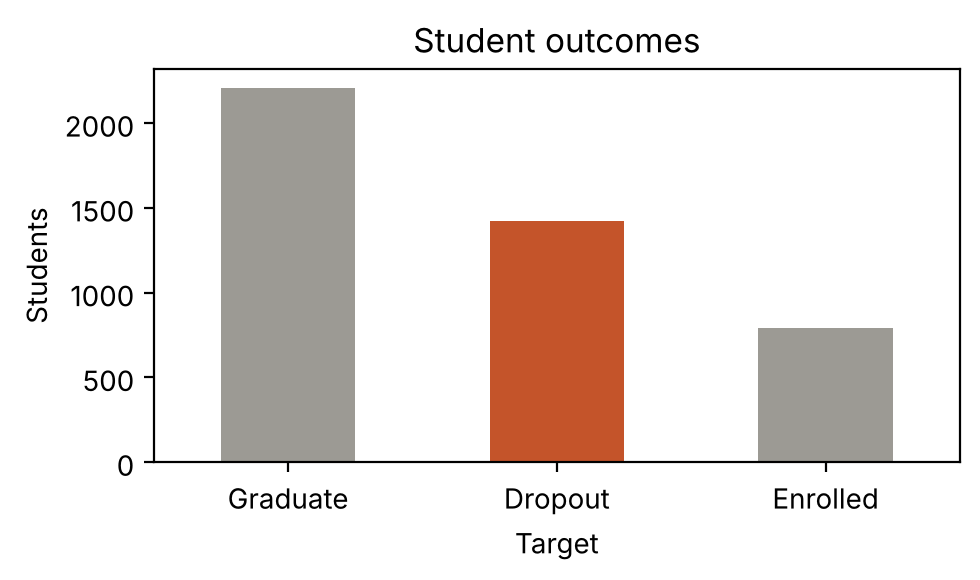

Dropout rate: 32.1%


In [4]:
counts = df["Target"].value_counts()
ax = counts.plot.bar(color=[RUST if c == "Dropout" else GREY for c in counts.index], rot=0, figsize=(5, 3), title="Student outcomes")
ax.set_ylabel("Students"); plt.tight_layout(); plt.show()

df["dropout"] = (df["Target"] == "Dropout").astype(int)
print(f"Dropout rate: {df['dropout'].mean():.1%}")

## 3 · Explore (EDA)
Where most of the insight came from, and where you earned your keep: talking to the people who know the students.

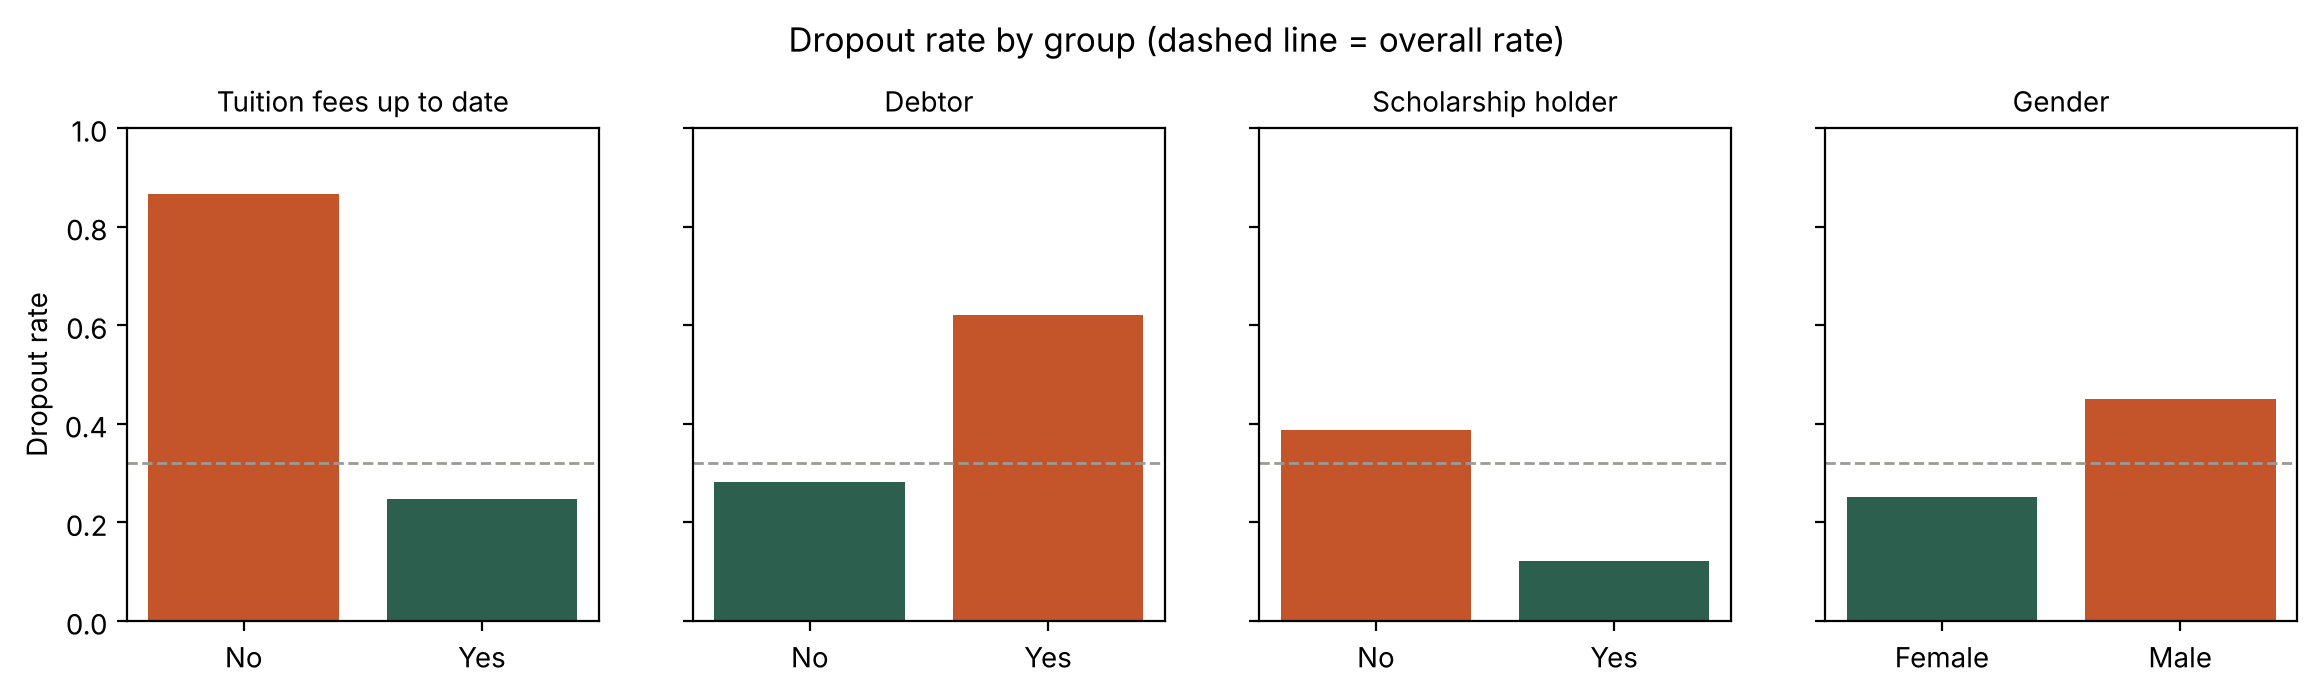

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, col, labels in zip(axes,
        ["Tuition fees up to date", "Debtor", "Scholarship holder", "Gender"],
        [["No", "Yes"], ["No", "Yes"], ["No", "Yes"], ["Female", "Male"]]):
    rate = df.groupby(col)["dropout"].mean()
    ax.bar([labels[int(i)] for i in rate.index], rate.values,
           color=[RUST if v > df["dropout"].mean() else GREEN for v in rate.values])   # rust = above-average risk
    ax.axhline(df["dropout"].mean(), color=GREY, lw=1, ls="--")
    ax.set_title(col, fontsize=10); ax.set_ylim(0, 1)
axes[0].set_ylabel("Dropout rate")
plt.suptitle("Dropout rate by group (dashed line = overall rate)", y=1.05); plt.show()

💡 **Students who are behind on tuition drop out at a much higher rate.** In 2017 this was the kind of finding that went straight onto a slide.

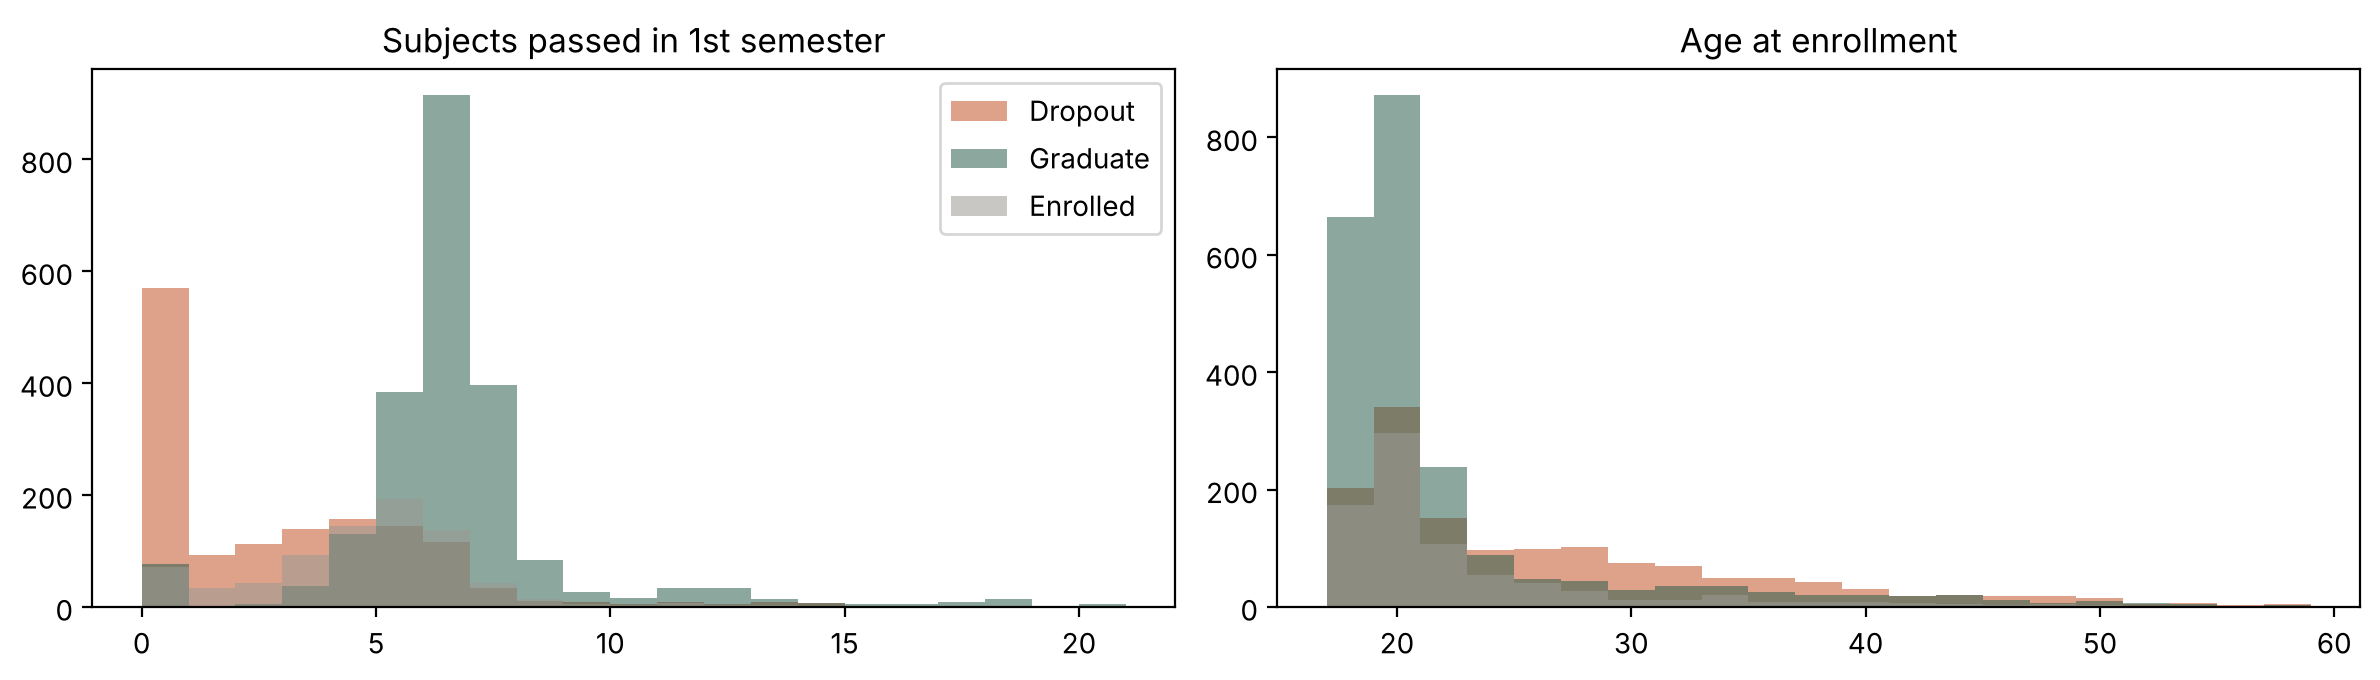

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for outcome, color in [("Dropout", RUST), ("Graduate", GREEN), ("Enrolled", GREY)]:
    sub = df[df["Target"] == outcome]
    axes[0].hist(sub["Curricular units 1st sem (approved)"], bins=range(0, 22), alpha=0.55, label=outcome, color=color)
    axes[1].hist(sub["Age at enrollment"], bins=range(17, 60, 2), alpha=0.55, label=outcome, color=color)
axes[0].set_title("Subjects passed in 1st semester"); axes[1].set_title("Age at enrollment")
axes[0].legend(); plt.tight_layout(); plt.show()

💡 **First-semester results tell you a lot.** Many dropouts passed *zero* subjects in their first semester. Older students at enrollment also drop out more often (often working students).

## 4 · Feature engineering, by hand
In 2017 this was where the "art" was. You'd turn domain intuition into columns:

In [7]:
def safe_ratio(a, b):
    return (a / b.replace(0, np.nan)).fillna(0)

df["pass_rate_1st"] = safe_ratio(df["Curricular units 1st sem (approved)"], df["Curricular units 1st sem (enrolled)"])
df["pass_rate_2nd"] = safe_ratio(df["Curricular units 2nd sem (approved)"], df["Curricular units 2nd sem (enrolled)"])
df["fee_problem"] = ((df["Debtor"] == 1) | (df["Tuition fees up to date"] == 0)).astype(int)
df["zero_passed_1st"] = (df["Curricular units 1st sem (approved)"] == 0).astype(int)

df.groupby("Target")[["pass_rate_1st", "pass_rate_2nd", "fee_problem", "zero_passed_1st"]].mean().round(2)

,pass_rate_1st,pass_rate_2nd,fee_problem,zero_passed_1st
Target,,,,
Dropout,0.38,0.29,0.39,0.40
Enrolled,0.69,0.65,0.14,0.09
Graduate,0.90,0.90,0.05,0.03


## 5 · Two models for two moments
A judgment call a model can't make for you: **when** does the office need the prediction?
- **At enrollment:** only background, admission and fee data. Early, but less information.
- **After 1st semester:** add first-semester grades. Later, but much more accurate.

Using 2nd-semester data to predict who drops out *during* the 2nd semester would be **leakage**: great scores that are useless in practice. So we leave it out.

⚖️ Notice we also feed in **Gender**, like many 2017 projects did without a second thought. Hold that thought. In 2026 you'd be expected to ask whether using it is fair, legal and necessary, and to test whether the model treats groups differently.

In [8]:
AT_ENROLLMENT = ["Age at enrollment", "Admission grade", "Previous qualification (grade)", "Gender",
                 "Scholarship holder", "Debtor", "Tuition fees up to date", "fee_problem", "Displaced",
                 "International", "Daytime/evening attendance", "Application order",
                 "Unemployment rate", "Inflation rate", "GDP"]
AFTER_1ST_SEM = AT_ENROLLMENT + ["Curricular units 1st sem (enrolled)", "Curricular units 1st sem (approved)",
                                 "Curricular units 1st sem (grade)", "Curricular units 1st sem (evaluations)",
                                 "pass_rate_1st", "zero_passed_1st"]

train, test = train_test_split(df, test_size=0.25, stratify=df["dropout"], random_state=42)
print(f"Train: {len(train):,} · Test: {len(test):,}")

Train: 3,318 · Test: 1,106


In [9]:
MODELS = {
    "Baseline (always 'no')": DummyClassifier(strategy="most_frequent"),
    "Logistic regression":    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random forest":          RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced", random_state=42),
}

rows, fitted = [], {}
for scenario, feats in [("At enrollment", AT_ENROLLMENT), ("After 1st semester", AFTER_1ST_SEM)]:
    for name, model in MODELS.items():
        m = clone(model).fit(train[feats], train["dropout"])
        p = m.predict_proba(test[feats])[:, 1]
        yhat = (p >= 0.5).astype(int)
        fitted[(scenario, name)] = (m, feats, p)
        rows.append({"scenario": scenario, "model": name,
                     "accuracy": accuracy_score(test["dropout"], yhat),
                     "precision": precision_score(test["dropout"], yhat, zero_division=0),
                     "recall": recall_score(test["dropout"], yhat),
                     "f1": f1_score(test["dropout"], yhat),
                     "roc_auc": roc_auc_score(test["dropout"], p)})

results = pd.DataFrame(rows).set_index(["scenario", "model"])
results.style.format("{:.2f}").background_gradient(cmap="Greens", subset=["recall", "roc_auc"])

💡 **Read the table like a 2017 data scientist:**
- The baseline gets ~68% *accuracy* by predicting "no one drops out", and catches **zero** dropouts. Accuracy alone is misleading on imbalanced data.
- **Recall** (the share of actual dropouts we catch) is what the office cares about.
- First-semester data makes the model much better. *When* you predict matters as much as *how*.

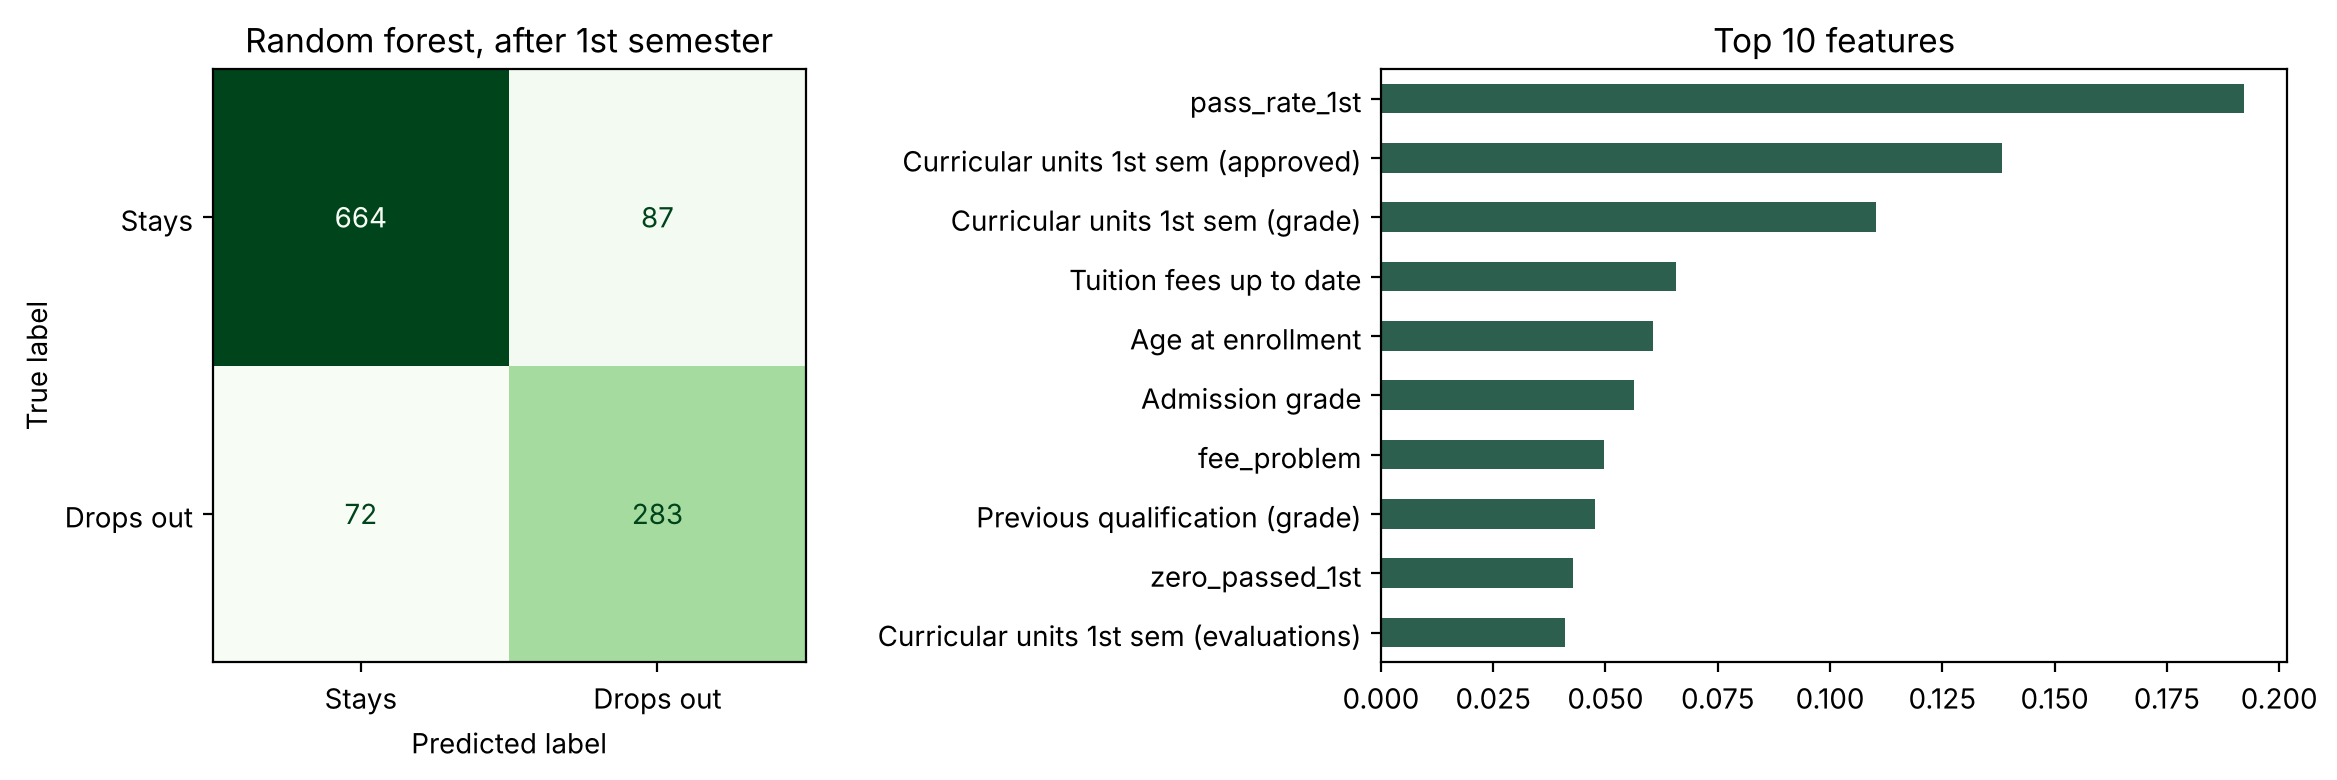

In [10]:
best_model, best_feats, best_p = fitted[("After 1st semester", "Random forest")]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay(confusion_matrix(test["dropout"], (best_p >= 0.5).astype(int)),
                       display_labels=["Stays", "Drops out"]).plot(ax=axes[0], cmap="Greens", colorbar=False)
axes[0].set_title("Random forest, after 1st semester")

imp = pd.Series(best_model.feature_importances_, index=best_feats).sort_values().tail(10)
imp.plot.barh(ax=axes[1], color=GREEN); axes[1].set_title("Top 10 features")
plt.tight_layout(); plt.show()

### Choosing a threshold is a business decision
At the default 0.5 cut-off we miss some dropouts. Lower the threshold and we catch more, but we also flag more students who were fine. Which mistake is worse? That's a question for the student affairs office, not for scikit-learn.

In [11]:
th = pd.DataFrame([{"threshold": t,
                    "dropouts caught (recall)": recall_score(test["dropout"], best_p >= t),
                    "flags that were right (precision)": precision_score(test["dropout"], best_p >= t),
                    "students flagged": int((best_p >= t).sum())} for t in [0.3, 0.4, 0.5, 0.6, 0.7]])
th.style.format({"threshold": "{:.1f}", "dropouts caught (recall)": "{:.0%}", "flags that were right (precision)": "{:.0%}"}).hide(axis="index")

threshold,dropouts caught (recall),flags that were right (precision),students flagged
0.3,88%,62%,498
0.4,84%,71%,423
0.5,80%,76%,370
0.6,74%,84%,316
0.7,65%,89%,261


## 6 · The slide 📊
And this is where a 2017 project usually ended:

In [12]:
r = results.loc[("After 1st semester", "Random forest")]
e = results.loc[("At enrollment", "Random forest")]
print("━" * 64)
print("  STUDENT DROPOUT EARLY-WARNING MODEL · Findings")
print("━" * 64)
print(f"  • {df['dropout'].mean():.0%} of students in the data dropped out")
print(f"  • After 1st semester, the model catches {r.recall:.0%} of dropouts (ROC AUC {r.roc_auc:.2f})")
print(f"  • At enrollment it catches {e.recall:.0%} (ROC AUC {e.roc_auc:.2f}): earlier, less accurate")
print(f"  • Strongest signals: {', '.join(imp.index[::-1][:3])}")
print("  • Recommendation: review flagged students after the 1st semester")
print("━" * 64)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  STUDENT DROPOUT EARLY-WARNING MODEL · Findings
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  • 32% of students in the data dropped out
  • After 1st semester, the model catches 80% of dropouts (ROC AUC 0.91)
  • At enrollment it catches 65% (ROC AUC 0.81): earlier, less accurate
  • Strongest signals: pass_rate_1st, Curricular units 1st sem (approved), Curricular units 1st sem (grade)
  • Recommendation: review flagged students after the 1st semester
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


---
## 🤔 Now what?
We can predict who's likely to drop out. In 2017, the project often stopped here: a model in a notebook and a slide in a deck. But the real goal was never *"predict dropout"*. It was ***"help fewer students drop out."*** And that raises questions this notebook can't answer:

- **Why** is *this* student at risk, explained in words an adviser can use?
- **What should the adviser say** to them, and what does the student handbook allow (fee extensions, leave of absence, scholarships)?
- **Can a student ask** "Am I at risk of losing my scholarship?" and get a grounded answer?
- **Did it work?** Did flagged students who got support actually stay?

Answering those needs documents, language, interaction and *system* evaluation. That's **Notebook 2: Data Science Now.** →

*(In the challenge, Mission D asks you to turn this exact model into a tool an AI agent can use.)*